# Part 6: Random forest and feature importance

**Data used:** the 21 training people only, with the saved person-wise folds (`results/folds.csv`). The 9 test people are untouched.
**Main metric:** macro-F1 over the 7 folds.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from config import SEED, DATA

X = pd.read_csv(DATA + "/train/X_train.txt", sep=r"\s+", header=None).values
y = np.loadtxt(DATA + "/train/y_train.txt", dtype=int)
groups = np.loadtxt(DATA + "/train/subject_train.txt", dtype=int)

# feature names; some names repeat in features.txt, so we keep the column number in front
names = pd.read_csv(DATA + "/features.txt", sep=r"\s+", header=None)[1].values
feature_names = np.array([str(i) + " " + n for i, n in enumerate(names)])

folds_table = pd.read_csv("results/folds.csv", index_col="person")["fold"]
fold_of_window = folds_table.loc[groups].values
saved_folds = PredefinedSplit(fold_of_window)

print(X.shape, fold_of_window.shape, saved_folds.get_n_splits())

(7352, 561) (7352,) 7


## How a random forest predicts
- A **decision tree** asks a chain of yes/no questions about single features, e.g. "is `tGravityAcc-mean()-X` below 0.1?", until it reaches a leaf that names an activity. Each question is chosen to make the groups as pure as possible (lowest Gini impurity).
- One deep tree memorises its training people (high variance). A **forest** trains many trees, each on a **bootstrap sample** of the windows and, at every split, only a **random subset of features** (`max_features`). The trees make different mistakes, and a **majority vote** averages them out.
- **No scaling needed:** a tree only asks "is this feature above or below a threshold?". Stretching or shifting a feature moves the threshold but never changes which windows go left or right. So `StandardScaler` would change nothing, and there is nothing to put in a pipeline.
- Settings:
  - `n_estimators` = number of trees. More trees = a more stable vote. It does **not** cause overfitting, it only costs time.
  - `max_depth` = how many questions a tree may ask. Shallower = simpler trees that cannot memorise single windows.
  - `max_features` = how many features each split may look at. Fewer = more different trees (more randomness).

In [2]:
train_rows = fold_of_window != 0
val_rows = fold_of_window == 0

start = time.time()
forest = RandomForestClassifier(random_state=SEED, n_jobs=-1)   # defaults: 100 trees, no depth limit, max_features="sqrt"
forest.fit(X[train_rows], y[train_rows])
print("fit time (s):", round(time.time() - start, 1))
print("fold 0 macro-F1:", round(f1_score(y[val_rows], forest.predict(X[val_rows]), average="macro"), 3))
print("training macro-F1:", round(f1_score(y[train_rows], forest.predict(X[train_rows]), average="macro"), 3))
print("tree depths:", min(t.get_depth() for t in forest.estimators_), "to", max(t.get_depth() for t in forest.estimators_))
print("features looked at per split ('sqrt'):", int(np.sqrt(X.shape[1])), "of", X.shape[1])

fit time (s): 1.2
fold 0 macro-F1: 0.902
training macro-F1: 1.0
tree depths: 14 to 24
features looked at per split ('sqrt'): 23 of 561


## Tuning on the saved folds
Grid: n_estimators in {100, 300, 500} × max_depth in {10, 20, None (no limit)} × max_features in {"sqrt" (= 23 features), 0.1 (= 56), 0.3 (= 168)} = 27 settings × 7 folds = 189 fits.

⚠️ **Slow cell: very slow.** It took **114 minutes** on battery power (Windows slows the CPU down on battery); with the charger plugged in we expect roughly 30–40 minutes (estimated from timing single fits). **Plug the laptop in before running.** 100 trees take 1–8 s to fit; `max_features=0.3` is the slowest because every split checks 168 features. Each forest uses all cores (`n_jobs=-1`). The results are saved in `results/cv_forest.csv`.

In [3]:
tree_values = [100, 300, 500]
depth_values = [10, 20, None]
feature_values = ["sqrt", 0.1, 0.3]
rows = []

start = time.time()
for n_trees in tree_values:
    for depth in depth_values:
        for max_feat in feature_values:
            forest = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, max_features=max_feat,
                                            random_state=SEED, n_jobs=-1)
            f1s = cross_val_score(forest, X, y, cv=saved_folds, scoring="f1_macro")
            setting = "n_estimators=" + str(n_trees) + " max_depth=" + str(depth) + " max_features=" + str(max_feat)
            for fold in range(7):
                rows.append({"model": "random_forest", "setting": setting, "fold": fold, "macro_f1": f1s[fold]})
            print(setting.ljust(52), " mean", round(f1s.mean(), 3), " spread", round(f1s.std(), 3))

cv_forest = pd.DataFrame(rows)
print("total time (min):", round((time.time() - start) / 60, 1))

n_estimators=100 max_depth=10 max_features=sqrt       mean 0.907  spread 0.038


n_estimators=100 max_depth=10 max_features=0.1        mean 0.903  spread 0.036


n_estimators=100 max_depth=10 max_features=0.3        mean 0.891  spread 0.041


n_estimators=100 max_depth=20 max_features=sqrt       mean 0.905  spread 0.039


n_estimators=100 max_depth=20 max_features=0.1        mean 0.902  spread 0.037


n_estimators=100 max_depth=20 max_features=0.3        mean 0.893  spread 0.041


... (17 outputs left out)

n_estimators=500 max_depth=20 max_features=0.3        mean 0.894  spread 0.042


n_estimators=500 max_depth=None max_features=sqrt     mean 0.908  spread 0.039


n_estimators=500 max_depth=None max_features=0.1      mean 0.903  spread 0.038


n_estimators=500 max_depth=None max_features=0.3      mean 0.894  spread 0.042
total time (min): 114.4


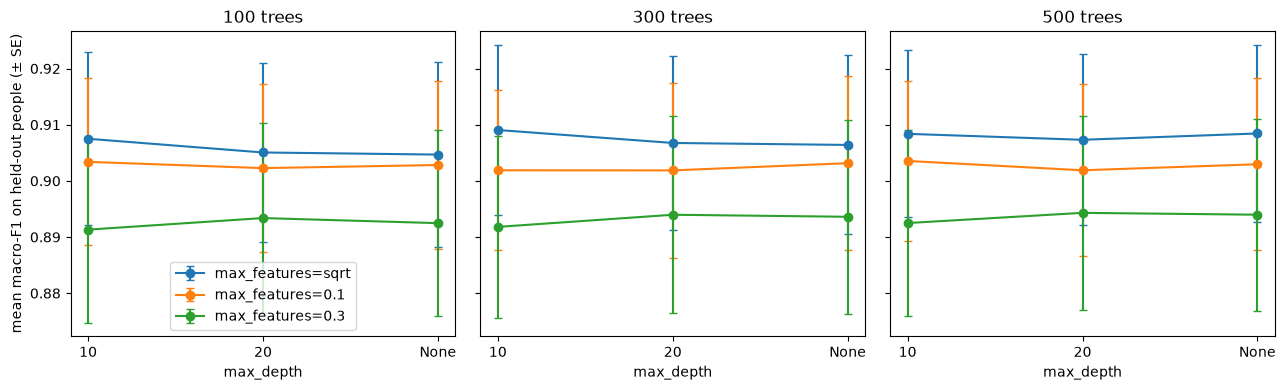

In [4]:
summary = cv_forest.groupby("setting", sort=False)["macro_f1"].agg(["mean", "std"])
summary["se"] = summary["std"] / np.sqrt(7)
summary["n_estimators"] = [n for n in tree_values for d in depth_values for f in feature_values]
summary["max_depth"] = [d for n in tree_values for d in depth_values for f in feature_values]
summary["max_features"] = [f for n in tree_values for d in depth_values for f in feature_values]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, n_trees in zip(axes, tree_values):
    for max_feat in feature_values:
        part = summary[(summary["n_estimators"] == n_trees) & (summary["max_features"] == max_feat)]
        ax.errorbar(range(3), part["mean"], yerr=part["se"], marker="o", capsize=3, label="max_features=" + str(max_feat))
    ax.set_xticks(range(3), ["10", "20", "None"])
    ax.set_xlabel("max_depth")
    ax.set_title(str(n_trees) + " trees")
axes[0].set_ylabel("mean macro-F1 on held-out people (± SE)")
axes[0].legend()
plt.tight_layout()
plt.show()

## Choosing a setting: the one-standard-error rule
SE = std over the 7 folds ÷ √7. The threshold is (best mean − best SE). Among the settings above the threshold, pick the **simplest**.

**Simplest for the forest** = shallowest trees first (`max_depth` 10 < 20 < no limit: fewer questions, less memorising), then fewest trees (cheaper, and easier to store and run on a phone), then fewest features per split ("sqrt" = 23 < 56 < 168: cheaper splits).

In [5]:
best_setting = summary["mean"].idxmax()
threshold = summary.loc[best_setting, "mean"] - summary.loc[best_setting, "se"]
print("best:", best_setting, " mean", round(summary.loc[best_setting, "mean"], 4),
      " SE", round(summary.loc[best_setting, "se"], 4), " threshold:", round(threshold, 4))

summary["depth_number"] = summary["max_depth"].map(lambda d: np.inf if d is None or pd.isna(d) else d)
summary["features_number"] = summary["max_features"].map({"sqrt": np.sqrt(561) / 561, 0.1: 0.1, 0.3: 0.3})

within = summary[summary["mean"] >= threshold].sort_values(["depth_number", "n_estimators", "features_number"])
print()
print("settings within one SE of the best (simplest first):")
print(within[["mean", "std", "se"]].round(4))

chosen = within.index[0]
chosen_params = summary.loc[chosen, ["n_estimators", "max_depth", "max_features"]].to_dict()
chosen_params["max_depth"] = None if chosen_params["max_depth"] is None or pd.isna(chosen_params["max_depth"]) else int(chosen_params["max_depth"])
print()
print("chosen (simplest within one SE):", chosen)

best: n_estimators=300 max_depth=10 max_features=sqrt  mean 0.9091  SE 0.0152  threshold: 0.8939

settings within one SE of the best (simplest first):
                                                     mean     std      se
setting                                                                  
n_estimators=100 max_depth=10 max_features=sqrt    0.9075  0.0407  0.0154
n_estimators=100 max_depth=10 max_features=0.1     0.9034  0.0394  0.0149
n_estimators=300 max_depth=10 max_features=sqrt    0.9091  0.0401  0.0152
n_estimators=300 max_depth=10 max_features=0.1     0.9019  0.0378  0.0143
n_estimators=500 max_depth=10 max_features=sqrt    0.9084  0.0394  0.0149
n_estimators=500 max_depth=10 max_features=0.1     0.9035  0.0375  0.0142
n_estimators=100 max_depth=20 max_features=sqrt    0.9051  0.0422  0.0160
n_estimators=100 max_depth=20 max_features=0.1     0.9023  0.0396  0.0150
n_estimators=300 max_depth=20 max_features=sqrt    0.9067  0.0411  0.0155
n_estimators=300 max_depth=20 max_f

In [6]:
cv_logistic = pd.read_csv("results/cv_logistic.csv")
cv_svm = pd.read_csv("results/cv_svm.csv")

def fold_scores(table, model_name, setting):
    part = table[(table["model"] == model_name) & (table["setting"] == setting)]
    return part.sort_values("fold")["macro_f1"].values

compare = pd.DataFrame({
    "logistic lasso C=0.1": fold_scores(cv_logistic, "logistic_L1", "C=0.1"),
    "SVM C=1 gamma=0.001": fold_scores(cv_svm, "svm_rbf", "C=1 gamma=0.001"),
    "forest (chosen)": fold_scores(cv_forest, "random_forest", chosen),
}, index=pd.Index(range(7), name="fold"))
print(compare.round(3))
print()
print(compare.agg(["mean", "std"]).round(3))

      logistic lasso C=0.1  SVM C=1 gamma=0.001  forest (chosen)
fold                                                            
0                    0.920                0.915            0.898
1                    0.965                0.950            0.838
2                    0.882                0.893            0.922
3                    0.963                0.955            0.942
4                    0.917                0.910            0.903
5                    0.909                0.931            0.886
6                    0.982                0.964            0.963

      logistic lasso C=0.1  SVM C=1 gamma=0.001  forest (chosen)
mean                 0.934                0.931            0.907
std                  0.036                0.027            0.041


In [7]:
cv_forest.to_csv("results/cv_forest.csv", index=False)

check = pd.read_csv("results/cv_forest.csv")
print("columns:", list(check.columns), "| same as cv_logistic:", list(check.columns) == list(cv_logistic.columns))
print("rows:", len(check), "| settings:", check["setting"].nunique(),
      "| rows per setting:", check.groupby("setting").size().unique())
print("missing values:", check.isna().sum().sum(), "| folds:", sorted(check["fold"].unique()))

columns: ['model', 'setting', 'fold', 'macro_f1'] | same as cv_logistic: True
rows: 189 | settings: 27 | rows per setting: [7]
missing values: 0 | folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


## Which features does the forest use? Two ways to measure importance
1. **Impurity importance** (`feature_importances_`): how much each feature's splits reduced impurity, summed over all trees. It is free, but it is measured on the **training** windows, so it can reward features that only helped the forest memorise.
2. **Permutation importance:** take the **held-out** people of a fold, shuffle one feature's column (this breaks its link to the activity), and measure how much macro-F1 drops. A big drop means the model really relies on that feature for **new people**.

We fit the chosen forest on each fold's 18 training people and measure both on that fold (permutation on the 3 held-out people), then average over the 7 folds.

⚠️ **Slow cell: about 5 minutes** (4.4 min in our run). Permutation importance shuffles each of the 561 features 3 times on each of the 7 folds (11,781 re-scorings).

In [8]:
from sklearn.inspection import permutation_importance

impurity = []
permutation = []
fitted = []

start = time.time()
for fold in range(7):
    train_rows = fold_of_window != fold
    val_rows = fold_of_window == fold
    forest = RandomForestClassifier(**chosen_params, random_state=SEED, n_jobs=-1)
    forest.fit(X[train_rows], y[train_rows])
    fitted.append(forest)
    impurity.append(forest.feature_importances_)
    forest.set_params(n_jobs=1)   # run the shuffles in parallel instead of the trees
    result = permutation_importance(forest, X[val_rows], y[val_rows], scoring="f1_macro",
                                    n_repeats=3, random_state=SEED, n_jobs=-1)
    permutation.append(result.importances_mean)
    forest.set_params(n_jobs=-1)
    print("fold", fold, "done,", round((time.time() - start) / 60, 1), "min")

importance = pd.DataFrame({
    "impurity": np.mean(impurity, axis=0),
    "permutation": np.mean(permutation, axis=0),
}, index=feature_names)

fold 0 done, 1.1 min


fold 1 done, 1.8 min


fold 2 done, 2.5 min


fold 3 done, 3.1 min


fold 4 done, 3.5 min


fold 5 done, 4.1 min


fold 6 done, 4.4 min


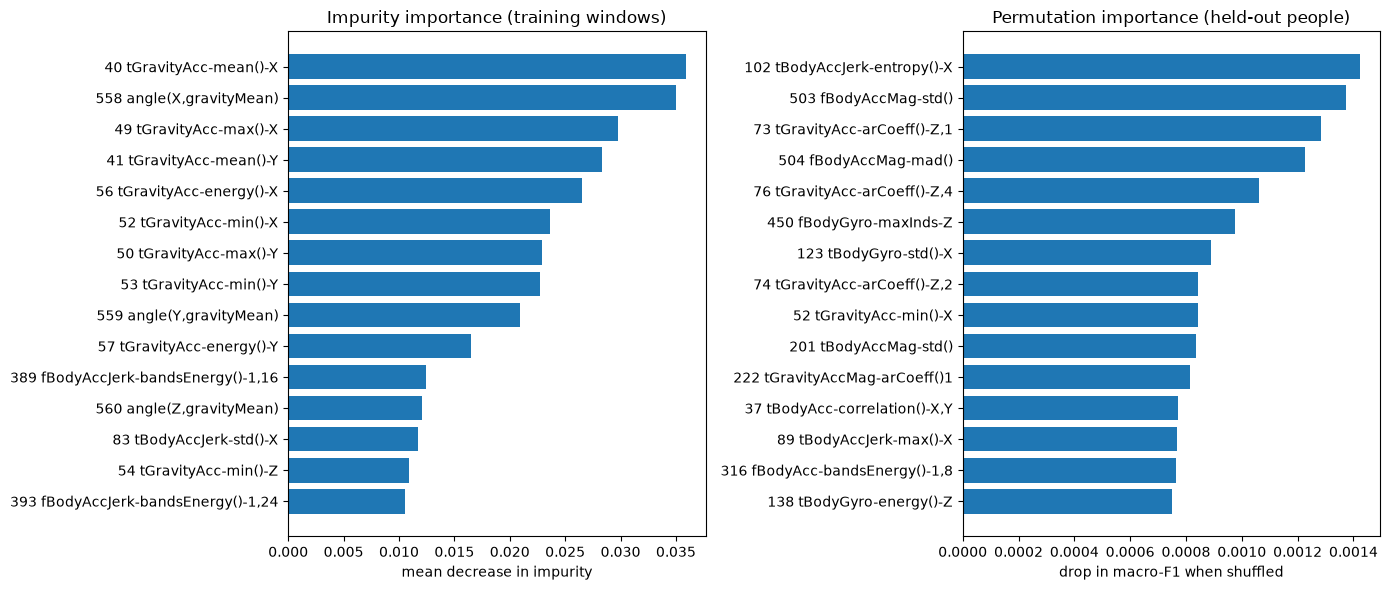

top 15 by impurity:
                                     impurity  permutation
40 tGravityAcc-mean()-X                0.0359       0.0006
558 angle(X,gravityMean)               0.0350       0.0007
49 tGravityAcc-max()-X                 0.0298       0.0005
41 tGravityAcc-mean()-Y                0.0284      -0.0032
56 tGravityAcc-energy()-X              0.0265      -0.0001
52 tGravityAcc-min()-X                 0.0236       0.0008
50 tGravityAcc-max()-Y                 0.0229      -0.0031
53 tGravityAcc-min()-Y                 0.0227      -0.0007
559 angle(Y,gravityMean)               0.0209       0.0001
57 tGravityAcc-energy()-Y              0.0165       0.0003
389 fBodyAccJerk-bandsEnergy()-1,16    0.0125      -0.0003
560 angle(Z,gravityMean)               0.0121      -0.0009
83 tBodyAccJerk-std()-X                0.0117       0.0001
54 tGravityAcc-min()-Z                 0.0109      -0.0014
393 fBodyAccJerk-bandsEnergy()-1,24    0.0105      -0.0000

top 15 by permutation:
            

In [9]:
top_impurity = importance.sort_values("impurity", ascending=False).head(15)
top_permutation = importance.sort_values("permutation", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_impurity.index[::-1], top_impurity["impurity"][::-1])
axes[0].set_title("Impurity importance (training windows)")
axes[0].set_xlabel("mean decrease in impurity")
axes[1].barh(top_permutation.index[::-1], top_permutation["permutation"][::-1])
axes[1].set_title("Permutation importance (held-out people)")
axes[1].set_xlabel("drop in macro-F1 when shuffled")
plt.tight_layout()
plt.show()

print("top 15 by impurity:")
print(top_impurity.round(4))
print()
print("top 15 by permutation:")
print(top_permutation.round(4))
print()
print("features in both top-15 lists:", len(set(top_impurity.index) & set(top_permutation.index)))
print("features whose shuffling changes macro-F1 by less than 0.001:", (importance["permutation"].abs() < 0.001).sum(), "of 561")
from scipy.stats import spearmanr
print("rank agreement of the two measures (Spearman):", round(spearmanr(importance["impurity"], importance["permutation"])[0], 3))

## Correlated features split the importance
Many of the 561 features are near-copies (Part 2). If two features carry the same information:
- **Impurity:** the trees use one copy in some splits and the other copy in others, so the credit is **split** between them and each looks less important than the information really is.
- **Permutation:** if we shuffle one copy, the forest can still use the other, so macro-F1 barely drops. Each copy looks **unimportant on its own**, even if the information is essential.

Test: take the top impurity feature, find all features with |r| > 0.9 with it, and shuffle them **one at a time** vs **all together** on the held-out people.

In [10]:
corr = np.corrcoef(X, rowvar=False)
top_feature = int(importance["impurity"].values.argmax())
copies = np.where(np.abs(corr[top_feature]) > 0.9)[0]
print("top impurity feature:", feature_names[top_feature])
print("features with |r| > 0.9 with it (including itself):", len(copies))
print(feature_names[copies][:15])

rng = np.random.default_rng(SEED)
alone, together = [], []
for fold in range(7):
    val_rows = fold_of_window == fold
    Xv, yv = X[val_rows], y[val_rows]
    base = f1_score(yv, fitted[fold].predict(Xv), average="macro")

    shuffled = Xv.copy()
    shuffled[:, top_feature] = rng.permutation(shuffled[:, top_feature])
    alone.append(base - f1_score(yv, fitted[fold].predict(shuffled), average="macro"))

    shuffled = Xv.copy()
    order = rng.permutation(len(Xv))
    shuffled[:, copies] = shuffled[order][:, copies]   # shuffle the whole group with the same order
    together.append(base - f1_score(yv, fitted[fold].predict(shuffled), average="macro"))

print()
print("drop in macro-F1, shuffling the top feature alone:      ", round(np.mean(alone), 4))
print("drop in macro-F1, shuffling it and all its near-copies:", round(np.mean(together), 4))
print("impurity importance of the feature alone:", round(importance["impurity"].iloc[top_feature], 4),
      " | of the whole group:", round(importance["impurity"].iloc[copies].sum(), 4))

top impurity feature: 40 tGravityAcc-mean()-X
features with |r| > 0.9 with it (including itself): 5
['40 tGravityAcc-mean()-X' '49 tGravityAcc-max()-X'
 '52 tGravityAcc-min()-X' '56 tGravityAcc-energy()-X'
 '558 angle(X,gravityMean)']



drop in macro-F1, shuffling the top feature alone:       0.0004
drop in macro-F1, shuffling it and all its near-copies: 0.1963
impurity importance of the feature alone: 0.0359  | of the whole group: 0.1508


# Part 6 summary: random forest and feature importance

**Data used:** the 21 training people only, with the saved person-wise folds. The 9 test people are untouched.

## Cell by cell
**Cell 1: load.** X, y, groups, the saved folds, and the 561 feature names (with the column number in front, because some names repeat in `features.txt`).

**Cell 2: one default forest on fold 0** (100 trees, no depth limit, 23 features per split). Fit in about 1 s. Macro-F1 **1.000 on the 18 training people** but **0.902 on the 3 new people**: each tree grows 14–24 levels deep and memorises its training windows. The vote averages much of this out, but not all.

**Cells 3–4: the grid (27 settings × 7 folds = 189 fits).**

| | max_features = sqrt (23) | 0.1 (56) | 0.3 (168) |
|---|---|---|---|
| range of mean macro-F1 over all trees/depths | 0.905–0.909 | 0.902–0.904 | 0.891–0.894 |

- **Almost nothing matters.** All 27 settings lie between **0.891 and 0.909**, while a single setting's scores vary over the folds with a std of about 0.04.
- **Number of trees and depth make no visible difference** (the lines in the plot are flat). More trees only make the vote more stable; depth 10 is already deep enough (2¹⁰ = 1,024 possible leaves for about 6,300 windows).
- **Fewer features per split is slightly better** (sqrt > 0.1 > 0.3). With 168 features per split, every tree picks the same strong gravity features, so the trees are more alike and the vote averages out less of their mistakes. With 23 features the trees are more different from each other.

**Cell 5: one-SE rule.** Best = 300 trees, depth 10, sqrt: 0.9091, SE 0.0152 → threshold **0.8939**. 21 of the 27 settings are within one SE. **Simplest = shallowest, then fewest trees, then fewest features per split** → **n_estimators = 100, max_depth = 10, max_features = "sqrt"** (0.9075 ± 0.0407 std, SE 0.0154).
- Why that order: shallower trees ask fewer questions and cannot memorise single windows; fewer trees are cheaper to store and run (relevant for a phone); fewer features per split = cheaper splits. Here the simplest setting is also within 0.002 of the best, so the choice costs nothing.

**Cell 6: comparison (same folds, same people).**

| Fold (people) | Lasso C=0.1 | SVM C=1 γ=0.001 | Forest (chosen) |
|---|---|---|---|
| 0 (15, 22, 25) | 0.920 | 0.915 | 0.898 |
| 1 (3, 8, 21) | 0.965 | 0.950 | **0.838** |
| 2 (14, 26, 29) | 0.882 | 0.893 | **0.922** |
| 3 (1, 6, 30) | 0.963 | 0.955 | 0.942 |
| 4 (7, 19, 28) | 0.917 | 0.910 | 0.903 |
| 5 (5, 16, 27) | 0.909 | 0.931 | 0.886 |
| 6 (11, 17, 23) | 0.982 | 0.964 | 0.963 |
| **mean ± std** | 0.934 ± 0.036 | 0.931 ± 0.027 | **0.907 ± 0.041** |

- The forest is **about 0.025 worse** than the other two and worse on 6 of 7 folds. The exception is fold 2 (the hardest people for the linear models), where it is the best of the three.
- Its worst fold is fold 1 (people 3, 8, 21): 0.838, where the other models score 0.95–0.965. This is worth a look in the error analysis (Part 8).
- A likely reason (not tested here): a tree splits on one feature at a time, with axis-aligned thresholds, while the 561 features were designed so that weighted sums of them separate the activities, which suits linear models and the SVM.

**Cell 7: saved** all 189 fold scores to `results/cv_forest.csv` (same 4 columns as `cv_logistic.csv`, 7 rows per setting, no missing values, folds 0–6).

**Cells 8–9: impurity vs permutation importance** (chosen forest, refitted on each fold; permutation on that fold's 3 held-out people, 3 shuffles per feature).
- **Impurity** ranks the **gravity features** on top: `tGravityAcc-mean()-X`, `angle(X,gravityMean)`, `tGravityAcc-max()-X`, ... These describe the phone's **orientation**, which separates lying from the rest and helps with sitting vs standing (Part 1).
- **Permutation** gives a completely different list: only **1 feature** appears in both top-15 lists, and the rank agreement is **0.039** (Spearman, about none).
- Every single feature's permutation importance is **tiny**: the largest drop is 0.0014, and **550 of 561 features change macro-F1 by less than 0.001** when shuffled. A few values are slightly negative, which means the drop is pure noise. With so many near-zero values, the permutation top-15 is mostly noise too, and we should not read it as a ranking.

**Cell 10: why: correlated features split the importance.**
- `tGravityAcc-mean()-X` has **4 near-copies** (|r| > 0.9): `tGravityAcc-max()-X`, `tGravityAcc-min()-X`, `tGravityAcc-energy()-X`, `angle(X,gravityMean)`. All 5 are in the impurity top 15.
- Shuffling it **alone**: macro-F1 drops by **0.0004**. Shuffling it **together with its 4 copies**: macro-F1 drops by **0.196**. The information is essential, but no single copy is, because the forest falls back on the others.
- Impurity importance of the feature alone: 0.036; of the group of 5: **0.151**. The trees spread the credit over the copies.
- This is the same reason lasso's chosen features changed from fold to fold in Part 4: with near-copies, *which* copy a model uses is close to arbitrary.

## Decision carried to Part 7
- **Random forest candidate: n_estimators = 100, max_depth = 10, max_features = "sqrt"** (macro-F1 **0.907 ± 0.041** std, SE 0.015), chosen by the one-SE rule as the simplest setting within one SE of the best (0.909).
- It is the weakest of the three model types on these folds.

## Five takeaways
1. A forest is a vote of many deep, slightly different trees. It needs **no scaling**, because trees only compare a feature with a threshold.
2. **The settings barely matter** (0.891–0.909 over 27 settings); fewer features per split is slightly better because it makes the trees more different from each other.
3. The forest (0.907) is **below logistic regression and the SVM** (about 0.93), except on the hardest fold.
4. Impurity and permutation importance **disagree almost completely** on single features, and almost no single feature matters on its own.
5. **Importance belongs to groups of correlated features, not single columns:** the X-gravity group of 5 features is worth 0.196 macro-F1, while any single copy is worth almost nothing.